# Lab 5: Linear Regression
1. with plant species data
2. with fake data
------



Lab TA: Lee Ochs

In [1]:
#load the correct environment/kernel (python 3 ipykernel)
#mine uses the base enviornment 
#if package does not load correctly, close notebook, type "conda activate base" in ur terminal, then type "jupyter notebook"
import pandas as pd #data frame
import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t
from scipy import stats

### Hypothesis: We have More Plant Species with Larger Island Area


Galapagos Islands are volcanic islands in the Eastern Pacific.\
Many Islands with different size and species abundance.

In [2]:
plant = pd.read_csv('Plant_Area.txt', sep='\s+')

#check the data

#practise
print(plant.head(10))

          Island    Area  Species
0      Albemarle  5824.9      325
1        Charles   165.8      319
2        Chatham   505.1      306
3          James   525.8      224
4  Indefatigable  1007.3      193
5       Abingdon    51.8      119
6         Duncan    18.4      103
7     Narborough   658.6       80
8           Hood    46.6       79
9        Seymour     2.6       52


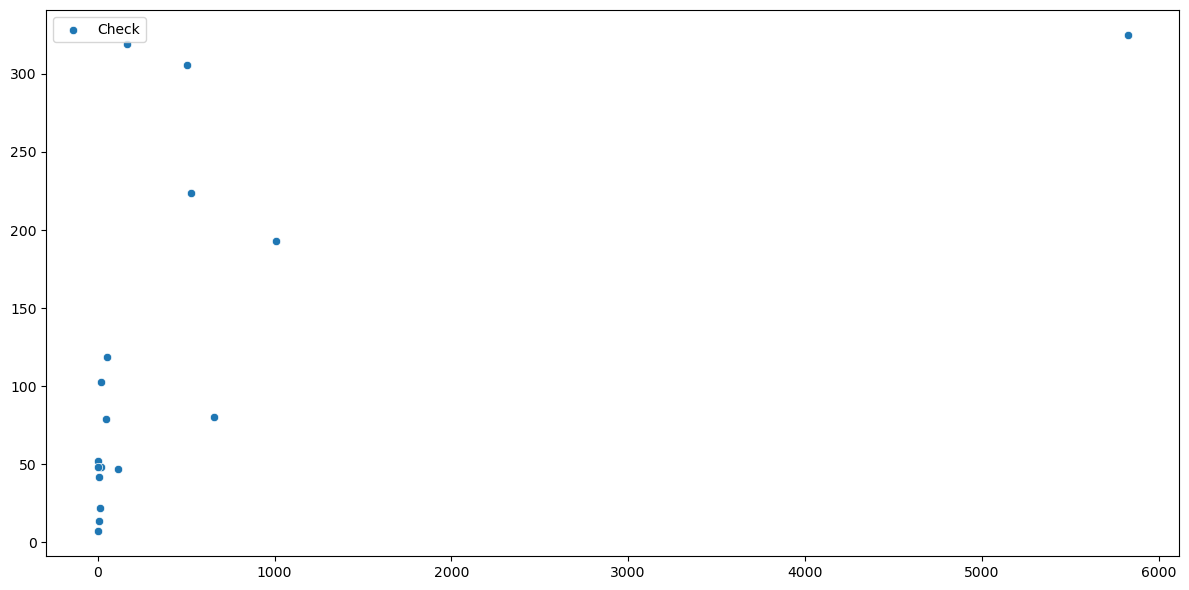

In [4]:

#examine the data by plotting a simple scatter plot between area vs species number 
#practise, plot the data species vs area
plt.figure(figsize=(12, 6))
sns.scatterplot(data= , x=, y=, label= )
plt.xlabel('')
plt.ylabel('')
plt.title('')

plt.tight_layout()
plt.show()


In [5]:
#we may need to log transform the data
# use the numpy log10 function, new data = np.log10(old data)
plant['log_Species'] = np.log10(plant['Species'])

#practise do the same for the area
plant['log_Area'] = np.log10(plant['Area'])

#check the data

In [6]:
#practise
#plot again,
#but two scatter plots, log species vs area
#and log species vs log area
#tell me what you see

Linear Regression Model

Y = ax + b

Calculate the slope a, intercpet b, r value, p value, standard error.


In [8]:
#there is a simple function to get all the values using 
#stats.linregress(X, Y)
#this function return slope, intercept, r value, p value, standard error

from scipy import stats


#calculate the regression model 
stats.linregress(plant['log_Area'], plant['log_Species'])



LinregressResult(slope=np.float64(0.32917225758140817), intercept=np.float64(1.322226751113036), rvalue=np.float64(0.7634495094184149), pvalue=np.float64(0.0003624120664113376), stderr=np.float64(0.07190195807021546), intercept_stderr=np.float64(0.1421630766836666))

In [9]:
# practise save the values into variables
# and print out the slope and r value



Lets reconstruct the regression line (see class slide) \

1. plot the regression line Y_predict = intercept + slope * X and plot x vs y
2. Calculate the confidence interval (e.g., 95%)

In [10]:
#constructing the regression line is pretty easy
#calcualte the predicted Y values using the regression line equation
#Y = ax + b

#practise: calculate the predicted y using the intercept and slope we got
#and plot
Y_predict = intercept + slope * X

plt.figure(figsize=(12, 6))
sns.lineplot(x=, y=, label= 'Regression Line')


NameError: name 'intercept' is not defined

Confidence interval = Y_predict +- t_value * standard error of the fit of the point (see slides)
- It is different for each X.
- We know Y_predict, so we need to calcualte the t_value and the standard error
- t_value can be calculated using t = t(significance level, df) 
- we will use the t function from scipy t_value = t.ppf(1-α/2, degrees_of_freedom) 


- standard error of the fit:$$SE_{fit}(x_i) = s_e \sqrt{\frac{1}{n} + \frac{(x_i - \bar{x})^2}{S_{xx}}}$$


- we need to calculate the standard error of estimate: $$s_e = \sqrt{\frac{SSE}{n-2}}$$
- Sum of squared errors: $$SSE = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
- For the sum of squared deviations of X from its mean. $$S_{xx} = \sum_{i=1}^{n}(x_i - \bar{x})^2$$

In [11]:
#calculate t_value
#specify the confidence level, sample size n, degree of freedom,
confidence = 0.95
alpha = 1 - confidence
n= 14 #n is the number of data points
degrees_of_freedom = n-2 #n is the number of data points

t_value = t.ppf(1 - alpha/2, degrees_of_freedom)

In [19]:
#now calculate the standard error of the fit
# lets tackle the Se first 
# standard error:Se = sqrt(Σ(residuals²) / df_residual)
Y= plant['log_Species']

residuals = Y - Y_predict

#check residuals
print(residuals)

se=np.sqrt(np.sum(residuals**2)/degrees_of_freedom)
#check se
print(se)


NameError: name 'Y_predict' is not defined

In [17]:
#now calculate 
X = plant['log_Area']
X_mean = np.mean(X)                    # Mean of X values
sxx = np.sum((X - X_mean)**2)  


In [18]:
#finally se_fit
se_fit = se * np.sqrt(1/n + (X - X_mean)**2 / sxx)

NameError: name 'se' is not defined

In [20]:
#set up confidence interval
upper = Y_predict + t_value * se_fit
lower = Y_predict - t_value * se_fit

NameError: name 'Y_predict' is not defined

In [21]:
#plot
plt.figure(figsize=(12, 6))
plt.fill_between(X, lower, upper, color='gray', alpha=0.5, label='95% Confidence Interval')
sns.scatterplot(data=plant, x='log_Area', y='log_Species', label= 'Data Points')
sns.lineplot(x=X, y=Y_predict, color='red', label= 'Regression Line')

plt.xlabel('Log Area')
plt.ylabel('Log Species')
plt.title('Species-Area Relationship with 95% Confidence Interval')
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'lower' is not defined

<Figure size 1200x600 with 0 Axes>

/var/folders/bp/7r8ytfmj3890ys07ql59p4x40000gn/T/ipykernel_72633/2647027378.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


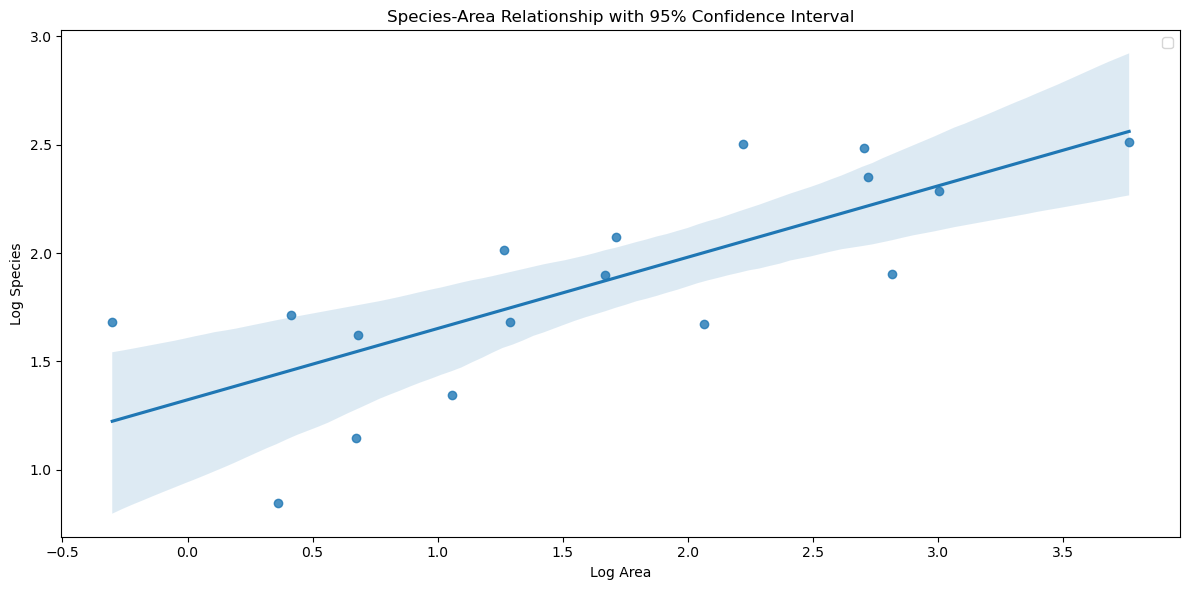

In [57]:

#there is easier ways to plot the confidence interval using sns pacakge
# --- IGNORE ---
plt.figure(figsize=(12, 6))
sns.regplot(data=plant, x='log_Area', y='log_Species', ci=95)
plt.xlabel('Log Area')
plt.ylabel('Log Species')
plt.title('Species-Area Relationship with 95% Confidence Interval')
plt.legend()
plt.tight_layout()
plt.show()

In reality, some data can be pretty messy/random/noisy\
How does the noise of data affect the regression performance?

In [22]:
#lets create some noisy data
#first, create a perfect linear relationship 
#for x, initiaze a range of values using np.linspace(a, b, n), a is start, b is end, n is number of points
#then create a linear relationship using y = cx + d, c is slope, d is intercept
x_perfect = np.linspace(0, 10, 10)
y_perfect = 2 * x_perfect + 3  # Perfect linear relationship


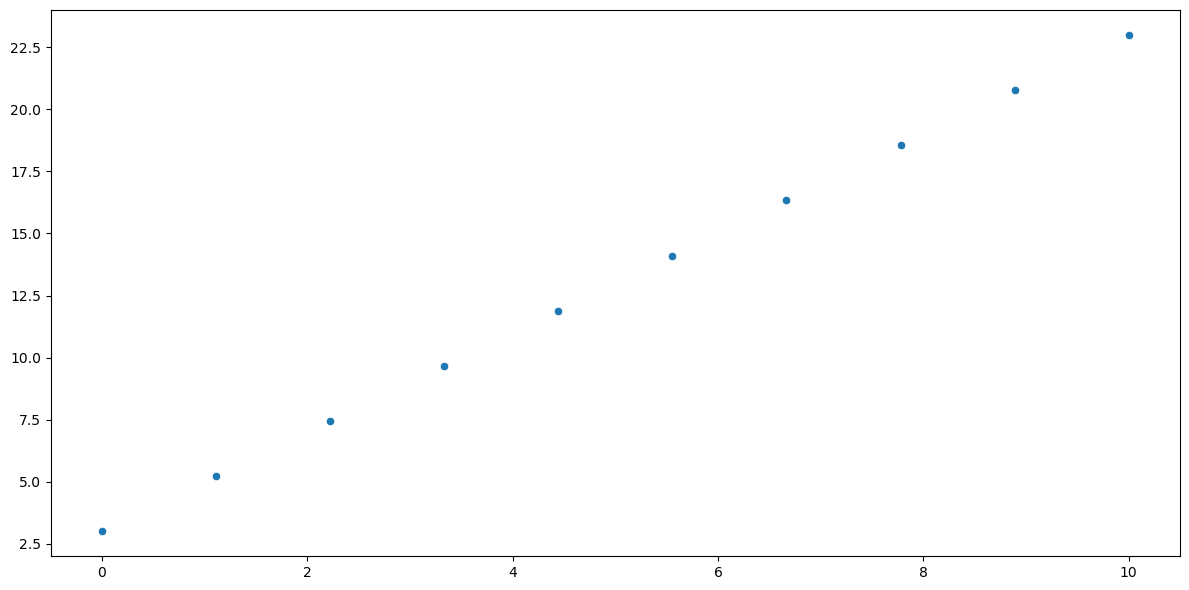

In [65]:
#examine the perfect data
plt.figure(figsize=(12, 6))
sns.scatterplot(x=x_perfect, y=y_perfect)
plt.tight_layout()
plt.show()

[0.2687885  0.11131898 0.25656968 0.83714389 0.64273648 0.42301716
 0.95472089 0.54249772 0.88136574 0.96924144]


<Axes: >

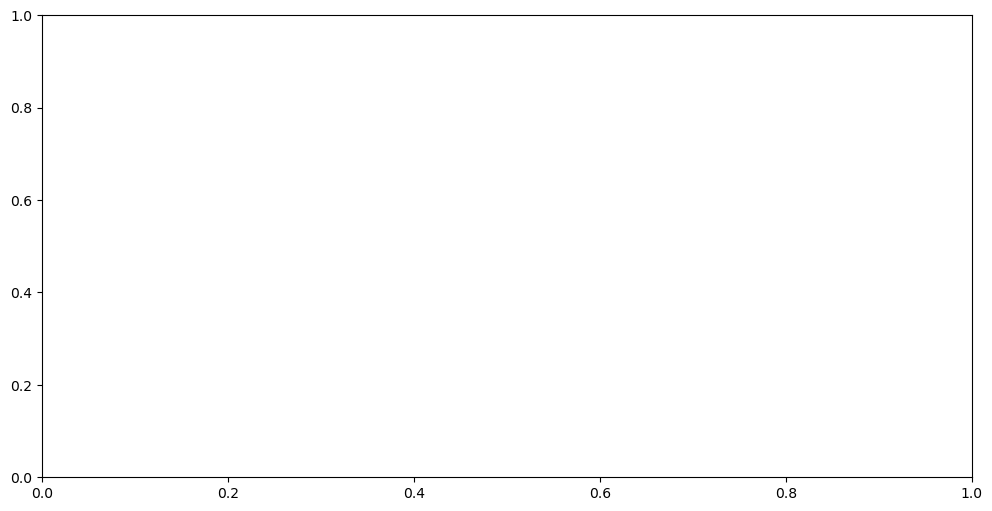

In [24]:
#now lets add some randomly generated number to every y values
#for example, lets create 10 random numbers between 0 and 1 using np.random.rand(10)
np.random.rand(10)

print(np.random.rand(10))

#add it to y_perfect
#y_noisy = y_perfect + np.random.rand(10)

#examine the noisy data
plt.figure(figsize=(12, 6))
sns.scatterplot()

#tell me what you see
#how about we add more noise by multiplying the random number by 10
#y_noisy2 = y_perfect + 10 * np.random.rand(10)
#plt.figure(figsize=(12, 6))
#sns.scatterplot(x=x_perfect, y=y_noisy2)



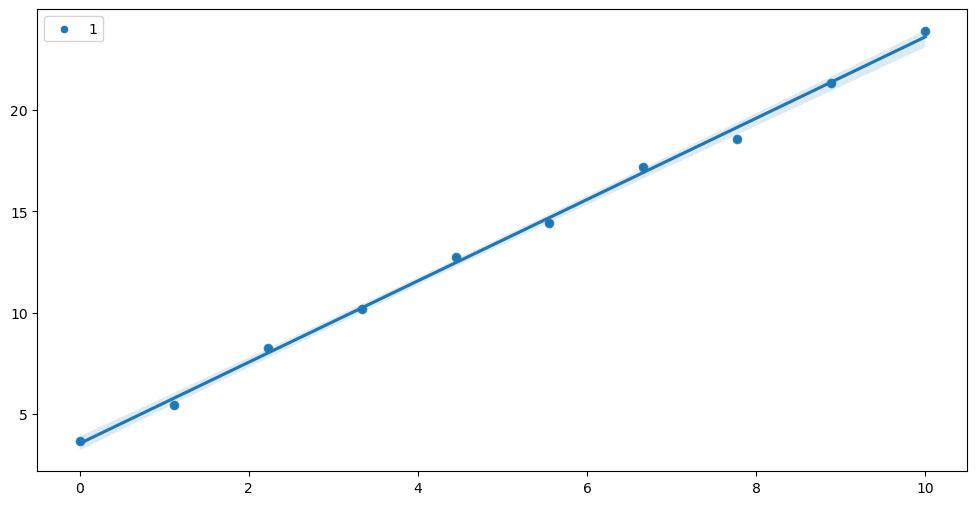

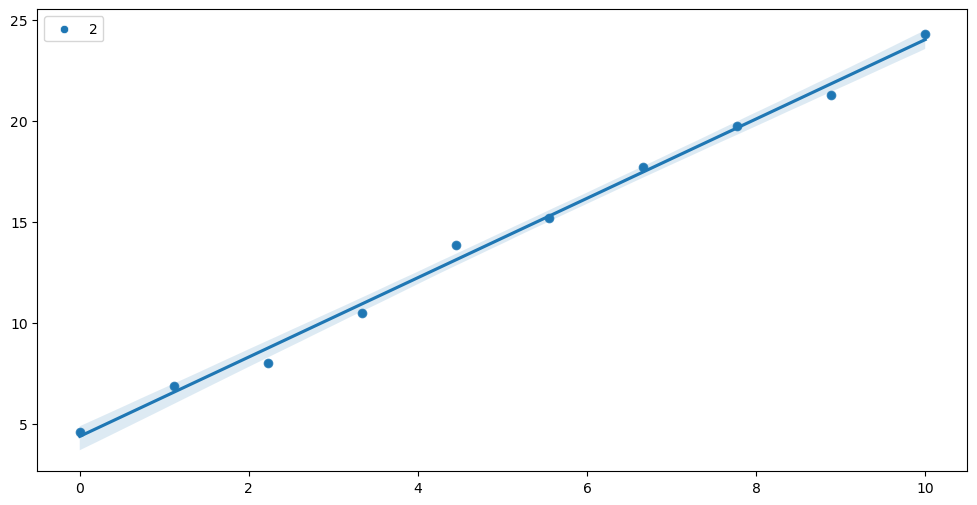

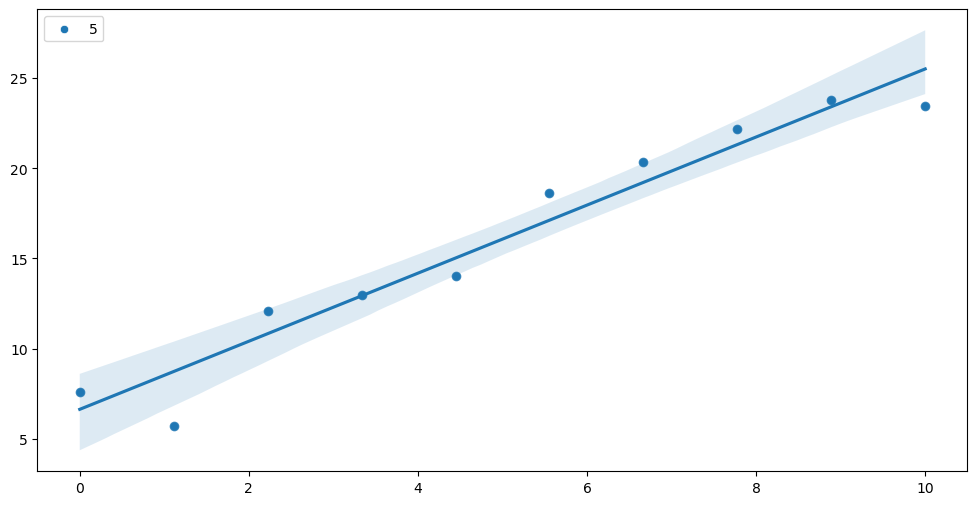

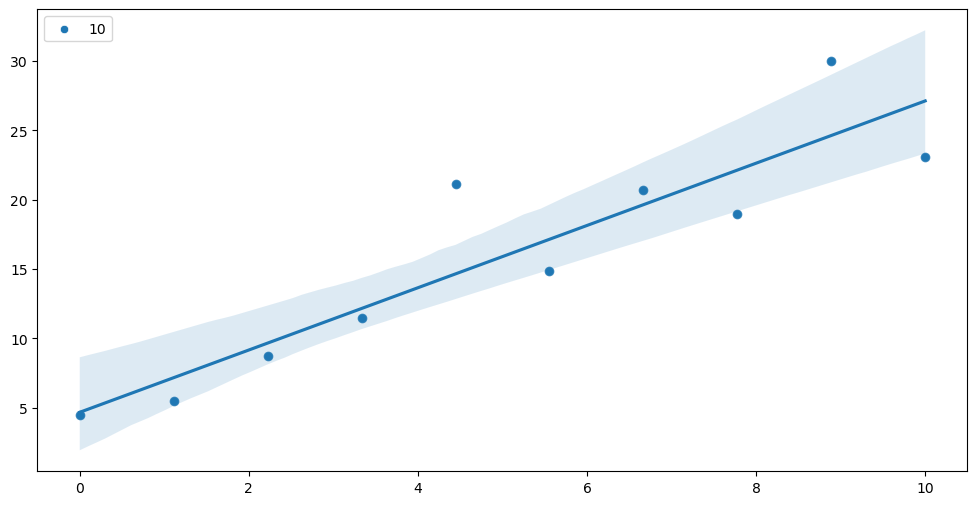

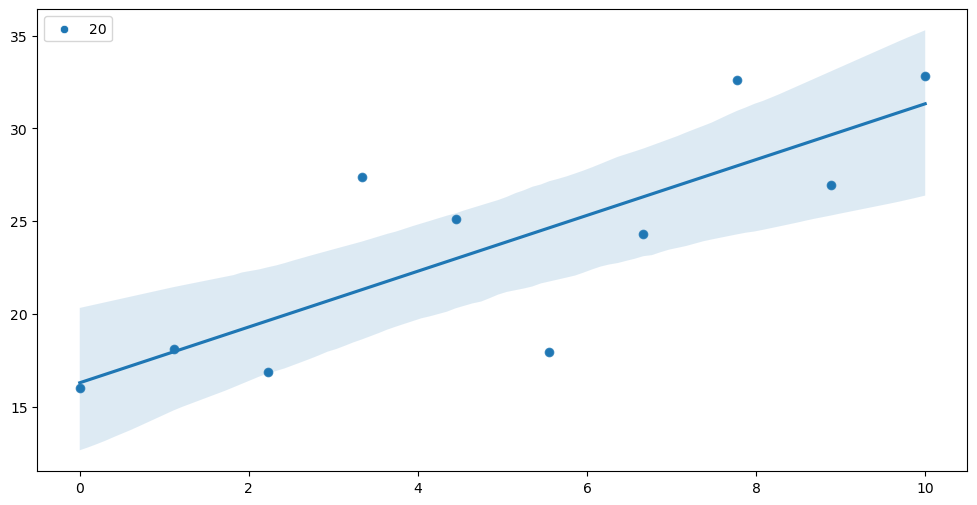

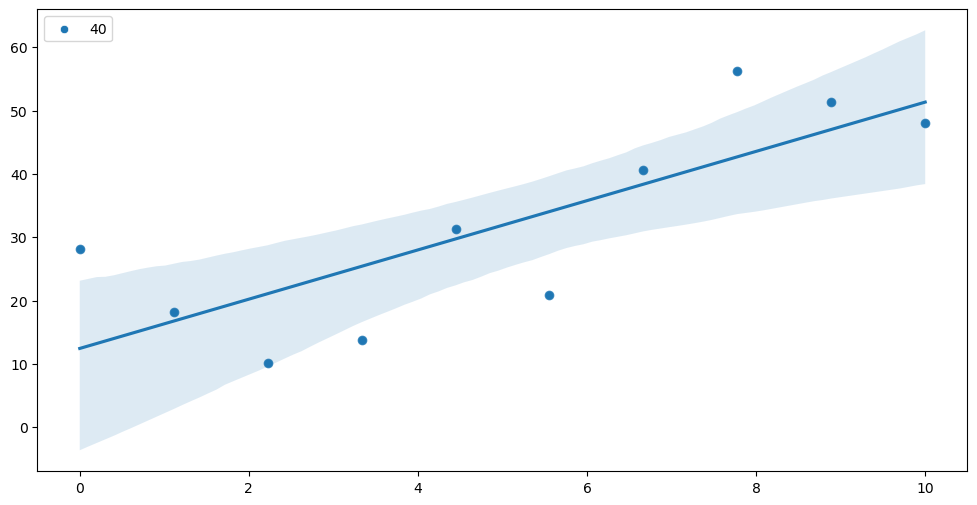

In [ ]:
#lets compare the effect of differnet noise level on regression
#by multlipying the random number by differnet levels 1, 2, 5,10,20,40
factors_multiple = [1, 2, 5, 10, 20, 40]

#use a for loop through the list and plot


for factor in factors_multiple:
    y_noise = y_perfect + factor * np.random.rand(10)
    plt.figure(figsize=(12, 6))
    sns.scatterplot(x=x_perfect, y=y_noise, label = factor)
    sns.regplot(x=x_perfect, y=y_noise, ci=95)
    

In [ ]:
#what about the p values and r number
#use the same function to get r and p for each factor and plot factor vs r and p
#slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)

In [ ]:
#practise
r_values = []
p_values = []

for factor in factors_multiple:
    y_noise = y_perfect + 
    #slope, intercept, r_value, p_value, std_err = stats.linregress(x_perfect, y_noise)
    #use the append funciton to append p and r
    
   

    

<Axes: >

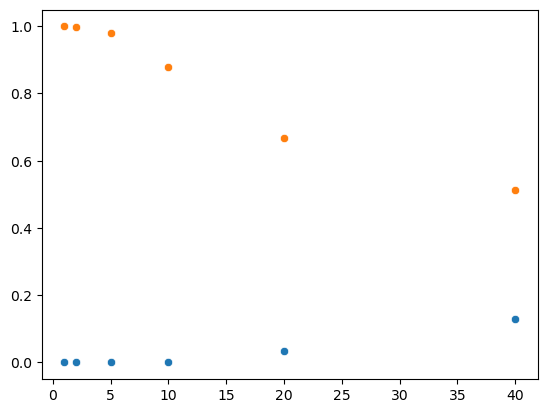

In [ ]:
#practise 
#use sns.scatterplot to plot the p values and r values vs factors, on the same plot, label them accordingly
sns.scatterplot(x=factors_multiple, y= p_values)
sns.scatterplot(x=factors_multiple, y= r_values)